# 2D Fast Fourier Transform (FFT) on an Image
This notebook demonstrates how to perform a 2D Fast Fourier Transform (FFT) on an image using NumPy. The steps include:
- Loading an image and converting it to grayscale.
- Visualizing the original grayscale image.
- Computing the row-wise FFT and visualizing the result.
- Computing the column-wise FFT and visualizing the result.
- Comparing the manual 2-step FFT with NumPy's efficient `fft2` function for 2D FFT.
The FFT is a powerful tool for analyzing the frequency components of images and signals. This notebook helps visualize how the 2D FFT transforms image data from the spatial domain to the frequency domain.

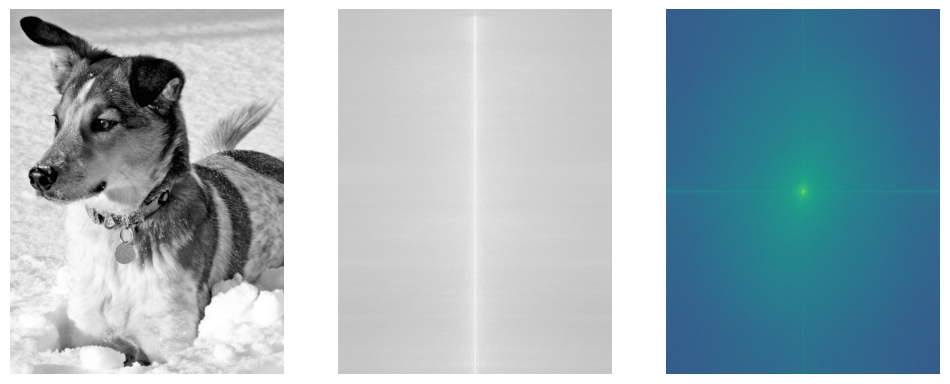

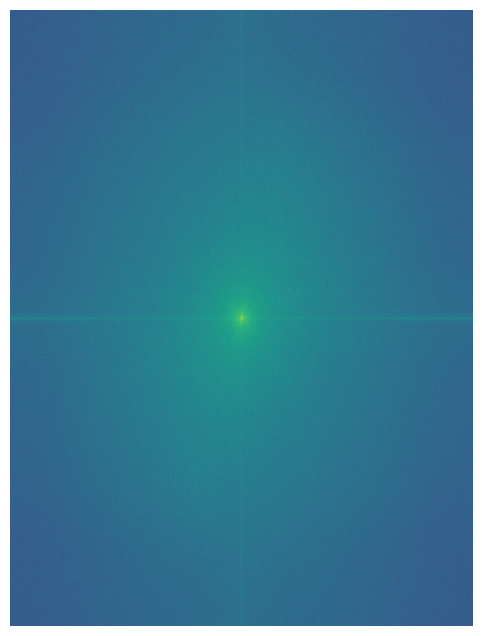

In [8]:
from matplotlib.image import imread
import numpy as np
import matplotlib.pyplot as plt
import os
plt.rcParams['figure.figsize'] = [12, 8]
plt.rcParams.update({'font.size': 18})

A = imread(os.path.join('..','DATA','dog.jpg'))
B = np.mean(A, -1); # Convert RGB to grayscale

fig,axs = plt.subplots(1,3)

# Plot image
img = axs[0].imshow(B)
img.set_cmap('gray')
axs[0].axis('off')

# Compute row-wise FFT

Cshift = np.zeros_like(B,dtype='complex')
C = np.zeros_like(B,dtype='complex')

for j in range(B.shape[0]):
    Cshift[j,:] = np.fft.fftshift(np.fft.fft(B[j,:]))
    C[j,:] = np.fft.fft(B[j,:])
    
img = axs[1].imshow(np.log(np.abs(Cshift)))
img.set_cmap('gray')
axs[1].axis('off')

# Compute column-wise FFT

D = np.zeros_like(C)
for j in range(C.shape[1]):
    D[:,j] = np.fft.fft(C[:,j])

img = axs[2].imshow(np.fft.fftshift(np.log(np.abs(D))))
#img.set_cmap('gray')
axs[2].axis('off')

plt.show()

# Much more efficient to use fft2
Df2 = np.fft.fft2(B)

# display Df2
plt.imshow(np.fft.fftshift(np.log(np.abs(Df2))))
plt.axis('off')
plt.show()


## Column-wise then Row-wise FFT
The following code computes the 2D FFT by first applying the FFT along the columns and then along the rows. This demonstrates that the order of applying FFTs (rows first or columns first) does not affect the final result, and both approaches are equivalent to using NumPy's `fft2` function.

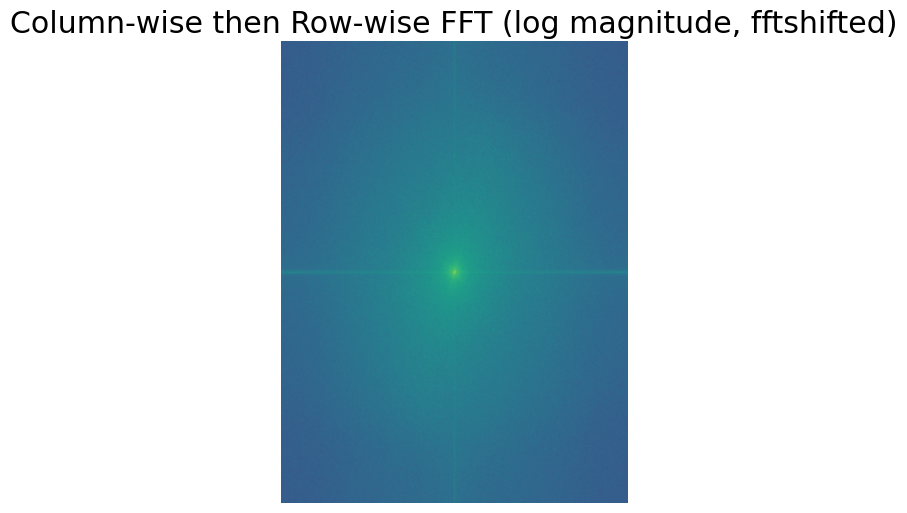

Are the row-col-fft vs col-row-fft equivalent? True
Are the fft2 vs row-col-fft methods equivalent? True


In [9]:
# Compute column-wise FFT first, then row-wise FFT
E = np.zeros_like(B, dtype='complex')
for j in range(B.shape[1]):
    E[:, j] = np.fft.fft(B[:, j])
for i in range(E.shape[0]):
    E[i, :] = np.fft.fft(E[i, :])
# Apply fftshift for visualization and comparison
Eshift = np.fft.fftshift(E)
plt.figure(figsize=(6, 6))
plt.imshow(np.log(np.abs(Eshift)))
plt.title('Column-wise then Row-wise FFT (log magnitude, fftshifted)')
plt.axis('off')
plt.show()
## Check equivalence with previous result (after fftshift)
print('Are the row-col-fft vs col-row-fft equivalent?', np.allclose(np.abs(np.fft.fftshift(D)), np.abs(Eshift)))

## Check equivalence with previous result (after fftshift)
print('Are the fft2 vs row-col-fft methods equivalent?', np.allclose(np.abs(np.fft.fftshift(Df2)), np.abs(Eshift)))